In [1]:
# =====================================
# HMM CNN MAMBA EXPERIMENT
# =====================================

import pandas as pd
import matplotlib.pyplot as plt
import torch

from src.run.model.run_hmm_cnn_mamba_classifier import RunHmmCnnMambaClassifier
from src.run.preprocess.config import _project_path


=== Running experiment with tol=0.01 ===

START PATIENT-WISE K-FOLD CROSS VALIDATION
Total patients: 75
Folds: 5


FOLD 01/5
Train patients: 60
Validation patients: 15
[WARNING] Mismatch in 00075__8_1.svc: expected 1663, found 1646.
[WARNING] Mismatch in 00075__8_1.svc: expected 1663, found 1646.
[Fold 01] Training Mamba model...
Fold 01 | Epoch 01 | train_loss=1.0142 | train_accuracy=0.5167 | train_f1=0.0000 | train_auc=0.7208 | train_precision=0.0000 | train_recall=0.0000 | train_specificity=1.0000 | val_loss=0.9520 | val_accuracy=0.4667 | val_f1=0.0000 | val_auc=0.7500 | val_precision=0.0000 | val_recall=0.0000 | val_specificity=1.0000
Fold 01 | Epoch 02 | train_loss=0.6471 | train_accuracy=0.6167 | train_f1=0.6849 | train_auc=0.7086 | train_precision=0.5682 | train_recall=0.8621 | train_specificity=0.3871 | val_loss=0.6470 | val_accuracy=0.5333 | val_f1=0.6957 | val_auc=0.8036 | val_precision=0.5333 | val_recall=1.0000 | val_specificity=0.0000
Fold 01 | Epoch 03 | train_loss=0.641

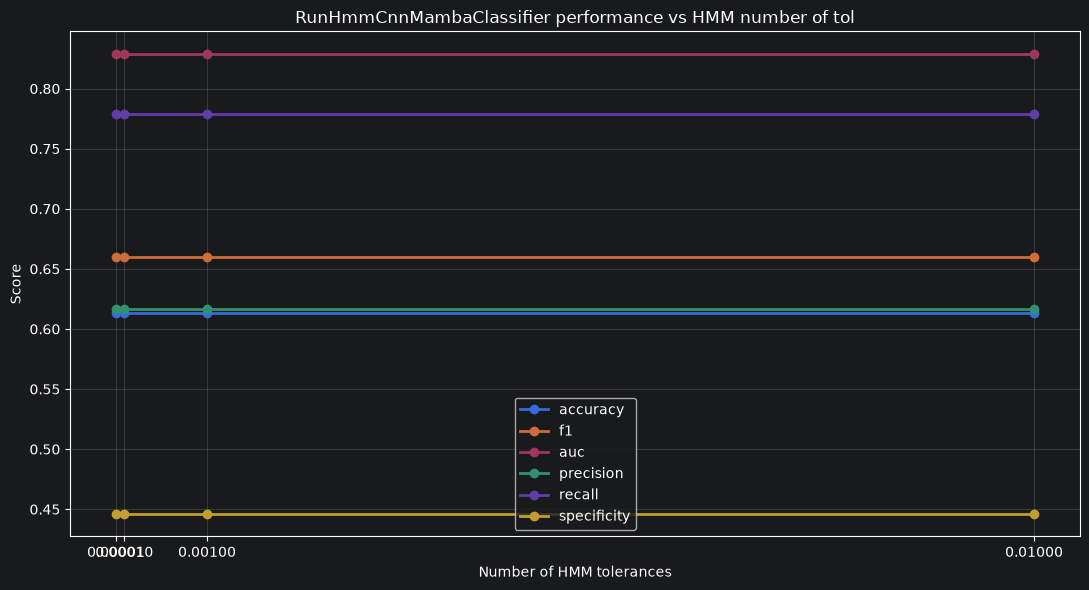


=== BEST HMM TOL ===
tol: 0
Accuracy: 0.6133
F1: 0.6597
AUC: 0.8286
Precision: 0.6164
Recall: 0.7786
Specificity: 0.4464


In [2]:
# HMM TOL

tols = [1e-2, 1e-3, 1e-4, 1e-5]

results = []

for t in tols:

    print(
        f"\n=== Running experiment with tol={t} ==="
    )

    runner = RunHmmCnnMambaClassifier(
        data_root=_project_path(
            "PaHaW/PaHaW/PaHaW_public"
        ),

        metadata_path=_project_path(
            "PaHaW/PaHaW/PaHaW_files/corpus_PaHaW.xlsx"
        ),

        # =====================================================
        # Configurazione dati
        # =====================================================

        tasks=[1, 8],

        feature_names=("x", "y"),

        engineered_features=(
            "pressure_derivative",
        ),

        # =====================================================
        # Training
        # =====================================================

        epochs=50,

        batch_size=16,

        learning_rate=1e-3,

        regularization=1e-6,

        # =====================================================
        # HMM
        # =====================================================

        n_states=2,
        covariance_type="diag",
        n_iter=100,
        tol=t,
        random_state=42,
        algorithm="viterbi",
        verbose=False,

        n_splits=5,

        normalize=True,

        device=(
            "cuda"
            if torch.cuda.is_available()
            else "cpu"
        ),

        output_dir=_project_path(
            f"experiments/test_iperparametri/"
            f"hmm_cnn_mamba(train seg - val no)/"
            f"hmm_tol/tol_{t}"
        ),

        training_cfg={
            "metrics": [
                "accuracy",
                "f1",
                "auc",
                "precision",
                "recall",
                "specificity",
            ],

            "monitor_metric": "auc",

            "early_stopping_patience": float("inf"),

            "min_delta": 0.0,

            "normalize": True,

            "normalization_eps": 1e-6,

            "results_writer": "csv",

            "save_metrics": True,
        },
    )

    summary = runner.run()

    row = {
        "tol": t,
    }

    row.update(
        summary["averages"]
    )

    results.append(row)


# =========================================================
# DATAFRAME
# =========================================================

df = pd.DataFrame(results).sort_values(
    "tol"
)

print("\n=== Summary ===")
print(df)


# =========================================================
# SAVE
# =========================================================

df.to_csv(
    "hmm_cnn_mamba_tol_summary.csv",
    index=False
)


# =========================================================
# PLOT
# =========================================================

metrics = [
    "val_accuracy",
    "val_f1",
    "val_auc",
    "val_precision",
    "val_recall",
    "val_specificity",
]

plt.figure(figsize=(11, 6))

for metric in metrics:

    plt.plot(
        df["tol"],
        df[metric],
        marker="o",
        linewidth=2,
        label=metric.replace("val_", "")
    )

plt.xticks(
    df["tol"]
)

plt.xlabel("Number of HMM tolerances")
plt.ylabel(metric)
plt.legend()
plt.tight_layout()

plt.ylabel("Score")

plt.title(
    "RunHmmCnnMambaClassifier performance vs HMM number of tol"
)

plt.grid(
    True,
    alpha=0.3
)

plt.legend()

plt.tight_layout()

plt.show()


# =========================================================
# BEST CONFIGURATION
# =========================================================

best = df.sort_values(
    by="val_auc",
    ascending=False
).iloc[0]

print("\n=== BEST HMM TOL ===")

print(
    f"tol: {int(best['tol'])}"
)

print(
    f"Accuracy: {best['val_accuracy']:.4f}"
)

print(
    f"F1: {best['val_f1']:.4f}"
)

print(
    f"AUC: {best['val_auc']:.4f}"
)

print(
    f"Precision: {best['val_precision']:.4f}"
)

print(
    f"Recall: {best['val_recall']:.4f}"
)

print(
    f"Specificity: {best['val_specificity']:.4f}"
)


=== Running experiment with n_iter=50 ===

START PATIENT-WISE K-FOLD CROSS VALIDATION
Total patients: 75
Folds: 5


FOLD 01/5
Train patients: 60
Validation patients: 15
[WARNING] Mismatch in 00075__8_1.svc: expected 1663, found 1646.
[WARNING] Mismatch in 00075__8_1.svc: expected 1663, found 1646.
[Fold 01] Training Mamba model...
Fold 01 | Epoch 01 | train_loss=1.0142 | train_accuracy=0.5167 | train_f1=0.0000 | train_auc=0.7208 | train_precision=0.0000 | train_recall=0.0000 | train_specificity=1.0000 | val_loss=0.9520 | val_accuracy=0.4667 | val_f1=0.0000 | val_auc=0.7500 | val_precision=0.0000 | val_recall=0.0000 | val_specificity=1.0000
Fold 01 | Epoch 02 | train_loss=0.6471 | train_accuracy=0.6167 | train_f1=0.6849 | train_auc=0.7086 | train_precision=0.5682 | train_recall=0.8621 | train_specificity=0.3871 | val_loss=0.6470 | val_accuracy=0.5333 | val_f1=0.6957 | val_auc=0.8036 | val_precision=0.5333 | val_recall=1.0000 | val_specificity=0.0000
Fold 01 | Epoch 03 | train_loss=0.64

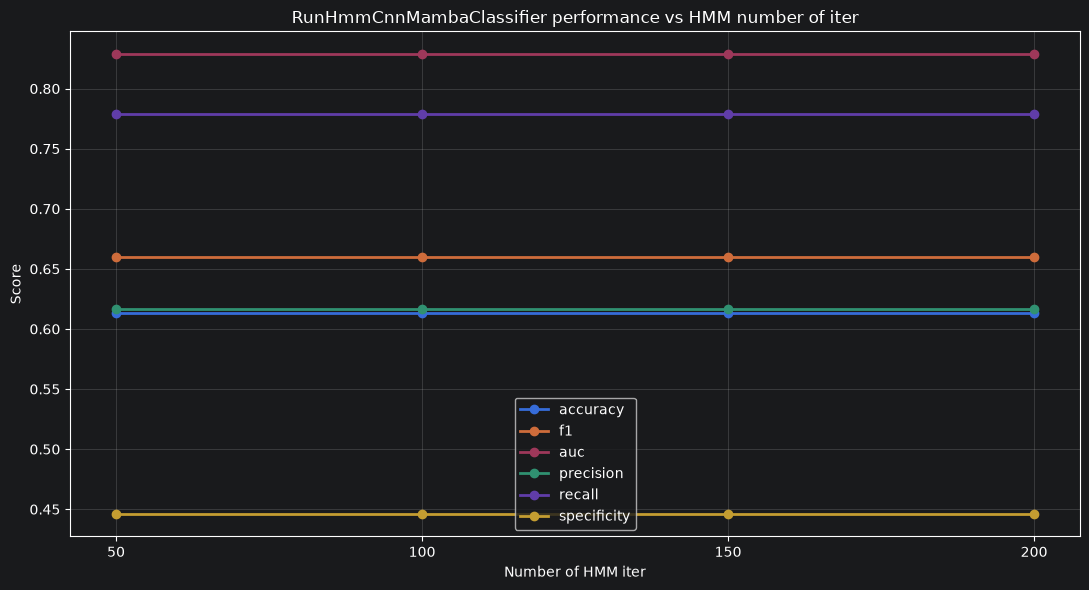


=== BEST HMM N_ITER ===
n_iter: 50
Accuracy: 0.6133
F1: 0.6597
AUC: 0.8286
Precision: 0.6164
Recall: 0.7786
Specificity: 0.4464


In [3]:
# HMM N_ITER

n_iter = [50, 100, 150, 200]

results = []

for i in n_iter:

    print(
        f"\n=== Running experiment with n_iter={i} ==="
    )

    runner = RunHmmCnnMambaClassifier(
        data_root=_project_path(
            "PaHaW/PaHaW/PaHaW_public"
        ),

        metadata_path=_project_path(
            "PaHaW/PaHaW/PaHaW_files/corpus_PaHaW.xlsx"
        ),

        # =====================================================
        # Configurazione dati
        # =====================================================

        tasks=[1, 8],

        feature_names=("x", "y"),

        engineered_features=(
            "pressure_derivative",
        ),

        # =====================================================
        # Training
        # =====================================================

        epochs=50,

        batch_size=16,

        learning_rate=1e-3,

        regularization=1e-6,

        # =====================================================
        # HMM
        # =====================================================

        n_states=2,
        covariance_type="diag",
        n_iter=i,
        tol=1e-2,
        random_state=42,
        algorithm="viterbi",
        verbose=False,

        n_splits=5,

        normalize=True,

        device=(
            "cuda"
            if torch.cuda.is_available()
            else "cpu"
        ),

        output_dir=_project_path(
            f"experiments/test_iperparametri/"
            f"hmm_cnn_mamba(train seg - val no)/"
            f"hmm_n_iter/iter_{i}"
        ),

        training_cfg={
            "metrics": [
                "accuracy",
                "f1",
                "auc",
                "precision",
                "recall",
                "specificity",
            ],

            "monitor_metric": "auc",

            "early_stopping_patience": float("inf"),

            "min_delta": 0.0,

            "normalize": True,

            "normalization_eps": 1e-6,

            "results_writer": "csv",

            "save_metrics": True,
        },
    )

    summary = runner.run()

    row = {
        "n_iter": i,
    }

    row.update(
        summary["averages"]
    )

    results.append(row)


# =========================================================
# DATAFRAME
# =========================================================

df = pd.DataFrame(results).sort_values(
    "n_iter"
)

print("\n=== Summary ===")
print(df)


# =========================================================
# SAVE
# =========================================================

df.to_csv(
    "hmm_cnn_mamba_n_iter_summary.csv",
    index=False
)


# =========================================================
# PLOT
# =========================================================

metrics = [
    "val_accuracy",
    "val_f1",
    "val_auc",
    "val_precision",
    "val_recall",
    "val_specificity",
]

plt.figure(figsize=(11, 6))

for metric in metrics:

    plt.plot(
        df["n_iter"],
        df[metric],
        marker="o",
        linewidth=2,
        label=metric.replace("val_", "")
    )

plt.xticks(
    df["n_iter"]
)

plt.xlabel("Number of HMM iter")

plt.ylabel("Score")

plt.title(
    "RunHmmCnnMambaClassifier performance vs HMM number of iter"
)

plt.grid(
    True,
    alpha=0.3
)

plt.legend()

plt.tight_layout()

plt.show()


# =========================================================
# BEST CONFIGURATION
# =========================================================

best = df.sort_values(
    by="val_auc",
    ascending=False
).iloc[0]

print("\n=== BEST HMM N_ITER ===")

print(
    f"n_iter: {int(best['n_iter'])}"
)

print(
    f"Accuracy: {best['val_accuracy']:.4f}"
)

print(
    f"F1: {best['val_f1']:.4f}"
)

print(
    f"AUC: {best['val_auc']:.4f}"
)

print(
    f"Precision: {best['val_precision']:.4f}"
)

print(
    f"Recall: {best['val_recall']:.4f}"
)

print(
    f"Specificity: {best['val_specificity']:.4f}"
)


=== Running experiment with epoch=50 ===

START PATIENT-WISE K-FOLD CROSS VALIDATION
Total patients: 75
Folds: 5


FOLD 01/5
Train patients: 60
Validation patients: 15
[WARNING] Mismatch in 00075__8_1.svc: expected 1663, found 1646.
[WARNING] Mismatch in 00075__8_1.svc: expected 1663, found 1646.
[Fold 01] Training Mamba model...
Fold 01 | Epoch 01 | train_loss=1.0142 | train_accuracy=0.5167 | train_f1=0.0000 | train_auc=0.7208 | train_precision=0.0000 | train_recall=0.0000 | train_specificity=1.0000 | val_loss=0.9520 | val_accuracy=0.4667 | val_f1=0.0000 | val_auc=0.7500 | val_precision=0.0000 | val_recall=0.0000 | val_specificity=1.0000
Fold 01 | Epoch 02 | train_loss=0.6471 | train_accuracy=0.6167 | train_f1=0.6849 | train_auc=0.7086 | train_precision=0.5682 | train_recall=0.8621 | train_specificity=0.3871 | val_loss=0.6470 | val_accuracy=0.5333 | val_f1=0.6957 | val_auc=0.8036 | val_precision=0.5333 | val_recall=1.0000 | val_specificity=0.0000
Fold 01 | Epoch 03 | train_loss=0.641

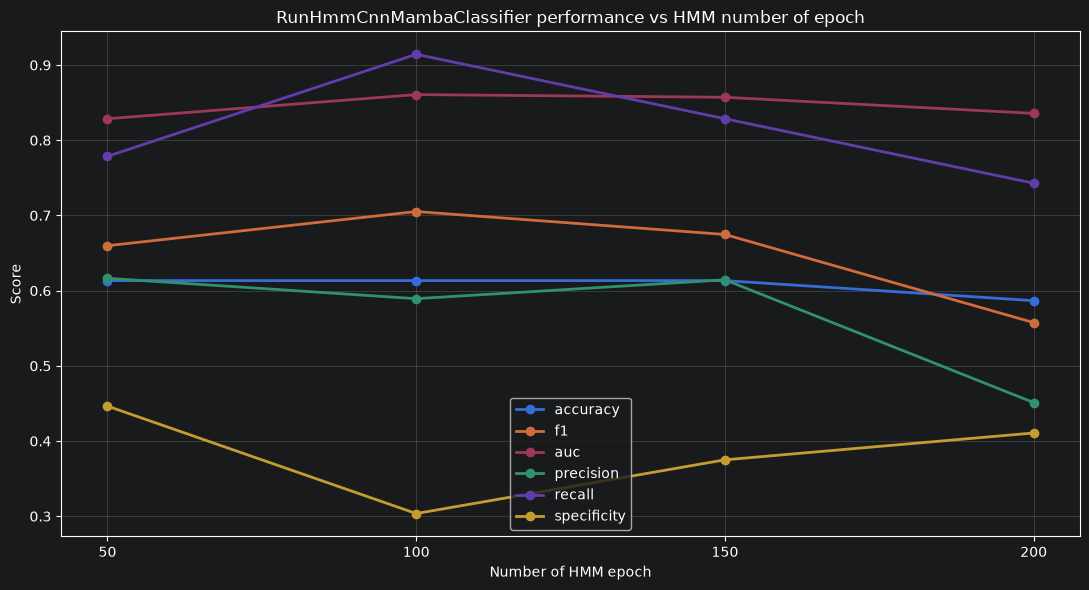


=== BEST HMM epoch ===
epoch: 100
Accuracy: 0.6133
F1: 0.7052
AUC: 0.8607
Precision: 0.5893
Recall: 0.9143
Specificity: 0.3036


In [4]:
# HMM EPOCH

epochs = [50, 100, 150, 200]

results = []

for e in epochs:

    print(
        f"\n=== Running experiment with epoch={e} ==="
    )

    runner = RunHmmCnnMambaClassifier(
        data_root=_project_path(
            "PaHaW/PaHaW/PaHaW_public"
        ),

        metadata_path=_project_path(
            "PaHaW/PaHaW/PaHaW_files/corpus_PaHaW.xlsx"
        ),

        # =====================================================
        # Configurazione dati
        # =====================================================

        tasks=[1, 8],

        feature_names=("x", "y"),

        engineered_features=(
            "pressure_derivative",
        ),

        # =====================================================
        # Training
        # =====================================================

        epochs=e,

        batch_size=16,

        learning_rate=1e-3,

        regularization=1e-6,

        # =====================================================
        # HMM
        # =====================================================

        n_states=2,
        covariance_type="diag",
        n_iter=50,
        tol=1e-2,
        random_state=42,
        algorithm="viterbi",
        verbose=False,

        n_splits=5,

        normalize=True,

        device=(
            "cuda"
            if torch.cuda.is_available()
            else "cpu"
        ),

        output_dir=_project_path(
            f"experiments/test_iperparametri/"
            f"hmm_cnn_mamba(train seg - val no)/"
            f"epoch/e_{e}"
        ),

        training_cfg={
            "metrics": [
                "accuracy",
                "f1",
                "auc",
                "precision",
                "recall",
                "specificity",
            ],

            "monitor_metric": "auc",

            "early_stopping_patience": float("inf"),

            "min_delta": 0.0,

            "normalize": True,

            "normalization_eps": 1e-6,

            "results_writer": "csv",

            "save_metrics": True,
        },
    )

    summary = runner.run()

    row = {
        "epoch": e,
    }

    row.update(
        summary["averages"]
    )

    results.append(row)


# =========================================================
# DATAFRAME
# =========================================================

df = pd.DataFrame(results).sort_values(
    "epoch"
)

print("\n=== Summary ===")
print(df)


# =========================================================
# SAVE
# =========================================================

df.to_csv(
    "hmm_cnn_mamba_epoch_summary.csv",
    index=False
)


# =========================================================
# PLOT
# =========================================================

metrics = [
    "val_accuracy",
    "val_f1",
    "val_auc",
    "val_precision",
    "val_recall",
    "val_specificity",
]

plt.figure(figsize=(11, 6))

for metric in metrics:

    plt.plot(
        df["epoch"],
        df[metric],
        marker="o",
        linewidth=2,
        label=metric.replace("val_", "")
    )

plt.xticks(
    df["epoch"]
)

plt.xlabel("Number of HMM epoch")
plt.ylabel(metric)
plt.legend()
plt.tight_layout()

plt.ylabel("Score")

plt.title(
    "RunHmmCnnMambaClassifier performance vs HMM number of epoch"
)

plt.grid(
    True,
    alpha=0.3
)

plt.legend()

plt.tight_layout()

plt.show()


# =========================================================
# BEST CONFIGURATION
# =========================================================

best = df.sort_values(
    by="val_auc",
    ascending=False
).iloc[0]

print("\n=== BEST HMM epoch ===")

print(
    f"epoch: {int(best['epoch'])}"
)

print(
    f"Accuracy: {best['val_accuracy']:.4f}"
)

print(
    f"F1: {best['val_f1']:.4f}"
)

print(
    f"AUC: {best['val_auc']:.4f}"
)

print(
    f"Precision: {best['val_precision']:.4f}"
)

print(
    f"Recall: {best['val_recall']:.4f}"
)

print(
    f"Specificity: {best['val_specificity']:.4f}"
)

In [5]:
# HMM LR

lrs = [1e-2, 1e-3, 1e-4, 2e-3, 2e-4]

results = []

for lr in lrs:

    print(
        f"\n=== Running experiment with lr={lr} ==="
    )

    runner = RunHmmCnnMambaClassifier(
        data_root=_project_path(
            "PaHaW/PaHaW/PaHaW_public"
        ),

        metadata_path=_project_path(
            "PaHaW/PaHaW/PaHaW_files/corpus_PaHaW.xlsx"
        ),

        # =====================================================
        # Configurazione dati
        # =====================================================

        tasks=[1, 8],

        feature_names=("x", "y"),

        engineered_features=(
            "pressure_derivative",
        ),

        # =====================================================
        # Training
        # =====================================================

        epochs=50,

        batch_size=16,

        learning_rate=lr,

        regularization=1e-6,

        # =====================================================
        # HMM
        # =====================================================

        n_states=2,
        covariance_type="diag",
        n_iter=50,
        tol=1e-2,
        random_state=42,
        algorithm="viterbi",
        verbose=False,

        n_splits=5,

        normalize=True,

        device=(
            "cuda"
            if torch.cuda.is_available()
            else "cpu"
        ),

        output_dir=_project_path(
            f"experiments/test_iperparametri/"
            f"hmm_cnn_mamba(train seg - val no)/"
            f"learning_rate/lr_{lr}"
        ),

        training_cfg={
            "metrics": [
                "accuracy",
                "f1",
                "auc",
                "precision",
                "recall",
                "specificity",
            ],

            "monitor_metric": "auc",

            "early_stopping_patience": float("inf"),

            "min_delta": 0.0,

            "normalize": True,

            "normalization_eps": 1e-6,

            "results_writer": "csv",

            "save_metrics": True,
        },
    )

    summary = runner.run()

    row = {
        "learning_rate": lr,
    }

    row.update(
        summary["averages"]
    )

    results.append(row)


# =========================================================
# DATAFRAME
# =========================================================

df = pd.DataFrame(results).sort_values(
    "lr"
)

print("\n=== Summary ===")
print(df)


# =========================================================
# SAVE
# =========================================================

df.to_csv(
    "hmm_cnn_mamba_learning_rate_summary.csv",
    index=False
)


# =========================================================
# PLOT
# =========================================================

metrics = [
    "val_accuracy",
    "val_f1",
    "val_auc",
    "val_precision",
    "val_recall",
    "val_specificity",
]

plt.figure(figsize=(11, 6))

for metric in metrics:

    plt.plot(
        df["learning_rate"],
        df[metric],
        marker="o",
        linewidth=2,
        label=metric.replace("val_", "")
    )

plt.xticks(
    df["learning_rate"]
)

plt.xlabel("Number of HMM learning_rate")
plt.ylabel(metric)
plt.legend()
plt.tight_layout()

plt.ylabel("Score")

plt.title(
    "RunHmmCnnMambaClassifier performance vs learning_rate"
)

plt.grid(
    True,
    alpha=0.3
)

plt.legend()

plt.tight_layout()

plt.show()


# =========================================================
# BEST CONFIGURATION
# =========================================================

best = df.sort_values(
    by="val_auc",
    ascending=False
).iloc[0]

print("\n=== BEST LR ===")

print(
    f"learning_rate: {int(best['learning_rate'])}"
)

print(
    f"Accuracy: {best['val_accuracy']:.4f}"
)

print(
    f"F1: {best['val_f1']:.4f}"
)

print(
    f"AUC: {best['val_auc']:.4f}"
)

print(
    f"Precision: {best['val_precision']:.4f}"
)

print(
    f"Recall: {best['val_recall']:.4f}"
)

print(
    f"Specificity: {best['val_specificity']:.4f}"
)


=== Running experiment with lr=0.01 ===

START PATIENT-WISE K-FOLD CROSS VALIDATION
Total patients: 75
Folds: 5


FOLD 01/5
Train patients: 60
Validation patients: 15
[WARNING] Mismatch in 00075__8_1.svc: expected 1663, found 1646.
[WARNING] Mismatch in 00075__8_1.svc: expected 1663, found 1646.
[Fold 01] Training Mamba model...
Fold 01 | Epoch 01 | train_loss=0.7071 | train_accuracy=0.5167 | train_f1=0.0000 | train_auc=0.6340 | train_precision=0.0000 | train_recall=0.0000 | train_specificity=1.0000 | val_loss=1.6355 | val_accuracy=0.4667 | val_f1=0.0000 | val_auc=0.2857 | val_precision=0.0000 | val_recall=0.0000 | val_specificity=1.0000
Fold 01 | Epoch 02 | train_loss=0.8814 | train_accuracy=0.5167 | train_f1=0.0000 | train_auc=0.5884 | train_precision=0.0000 | train_recall=0.0000 | train_specificity=1.0000 | val_loss=0.6933 | val_accuracy=0.5333 | val_f1=0.6957 | val_auc=0.2500 | val_precision=0.5333 | val_recall=1.0000 | val_specificity=0.0000
Fold 01 | Epoch 03 | train_loss=0.7549

KeyError: 'lr'


=== Running experiment with regularization=1e-08 ===

START PATIENT-WISE K-FOLD CROSS VALIDATION
Total patients: 75
Folds: 5


FOLD 01/5
Train patients: 60
Validation patients: 15
[WARNING] Mismatch in 00075__8_1.svc: expected 1663, found 1646.
[WARNING] Mismatch in 00075__8_1.svc: expected 1663, found 1646.
[Fold 01] Training Mamba model...
Fold 01 | Epoch 01 | train_loss=0.6624 | train_accuracy=0.6167 | train_f1=0.6667 | train_auc=0.6963 | train_precision=0.5750 | train_recall=0.7931 | train_specificity=0.4516 | val_loss=0.7125 | val_accuracy=0.5333 | val_f1=0.6957 | val_auc=0.3750 | val_precision=0.5333 | val_recall=1.0000 | val_specificity=0.0000
Fold 01 | Epoch 02 | train_loss=0.6789 | train_accuracy=0.5167 | train_f1=0.0000 | train_auc=0.7130 | train_precision=0.0000 | train_recall=0.0000 | train_specificity=1.0000 | val_loss=0.7234 | val_accuracy=0.5333 | val_f1=0.2222 | val_auc=0.6786 | val_precision=1.0000 | val_recall=0.1250 | val_specificity=1.0000
Fold 01 | Epoch 03 | trai

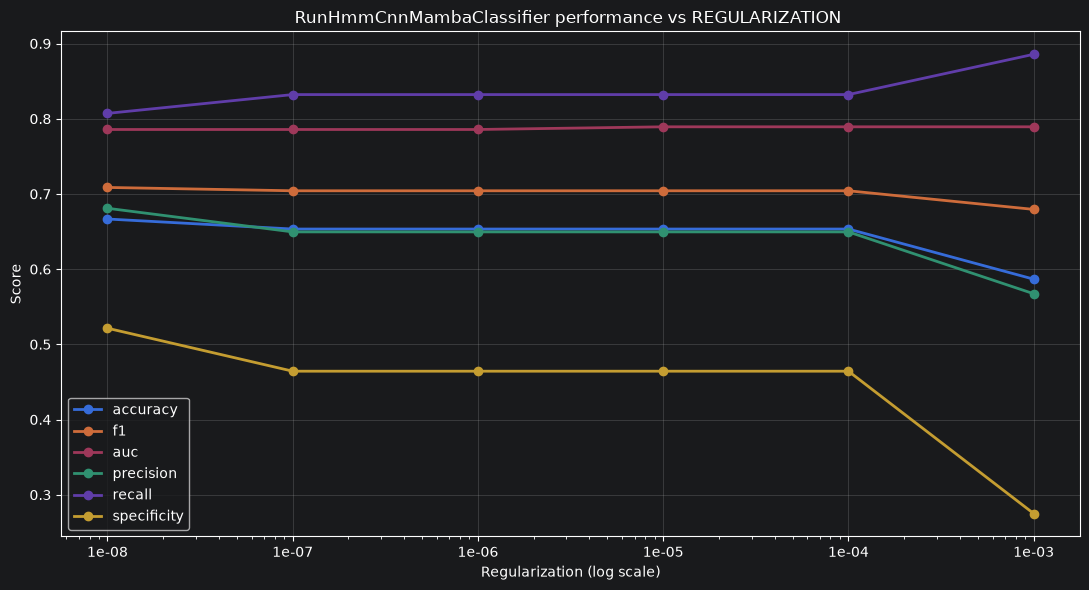


=== BEST REGULARIZATION ===
regularization: 1e-04
Accuracy: 0.6533
F1: 0.7042
AUC: 0.7893
Precision: 0.6495
Recall: 0.8321
Specificity: 0.4643


In [6]:
# HMM REGULARIZATION SWEEP

regs = [1e-8, 1e-7, 1e-6, 1e-5, 1e-4, 1e-3]

results = []

for reg in regs:

    print(
        f"\n=== Running experiment with regularization={reg:.0e} ==="
    )

    runner = RunHmmCnnMambaClassifier(
        data_root=_project_path(
            "PaHaW/PaHaW/PaHaW_public"
        ),

        metadata_path=_project_path(
            "PaHaW/PaHaW/PaHaW_files/corpus_PaHaW.xlsx"
        ),

        # =====================================================
        # Configurazione dati
        # =====================================================

        tasks=[1, 8],

        feature_names=("x", "y"),

        engineered_features=(
            "pressure_derivative",
        ),

        # =====================================================
        # Training
        # =====================================================

        epochs=50,

        batch_size=16,

        learning_rate=1e-4,

        regularization=reg,

        # =====================================================
        # HMM
        # =====================================================

        n_states=2,
        covariance_type="diag",
        n_iter=50,
        tol=1e-2,
        random_state=42,
        algorithm="viterbi",
        verbose=False,

        n_splits=5,

        normalize=True,

        device=(
            "cuda"
            if torch.cuda.is_available()
            else "cpu"
        ),

        output_dir=_project_path(
            f"experiments/test_iperparametri/"
            f"hmm_cnn_mamba(train seg - val no)/"
            f"regularization/reg_{reg:.0e}"
        ),

        training_cfg={
            "metrics": [
                "accuracy",
                "f1",
                "auc",
                "precision",
                "recall",
                "specificity",
            ],

            "monitor_metric": "auc",

            "early_stopping_patience": float("inf"),

            "min_delta": 0.0,

            "normalize": True,

            "normalization_eps": 1e-6,

            "results_writer": "csv",

            "save_metrics": True,
        },
    )

    summary = runner.run()

    row = {
        "regularization": reg,
    }

    row.update(
        summary["averages"]
    )

    results.append(row)


# =========================================================
# DATAFRAME
# =========================================================

df = pd.DataFrame(results).sort_values(
    "regularization"
)

print("\n=== Summary ===")
print(df)


# =========================================================
# SAVE
# =========================================================

df.to_csv(
    "hmm_cnn_mamba_regularization_summary.csv",
    index=False
)


# =========================================================
# PLOT
# =========================================================

metrics = [
    "val_accuracy",
    "val_f1",
    "val_auc",
    "val_precision",
    "val_recall",
    "val_specificity",
]

plt.figure(figsize=(11, 6))

for metric in metrics:

    plt.plot(
        df["regularization"],
        df[metric],
        marker="o",
        linewidth=2,
        label=metric.replace("val_", "")
    )

plt.xscale("log")

plt.xticks(
    df["regularization"],
    [f"{r:.0e}" for r in df["regularization"]]
)

plt.xlabel("Regularization (log scale)")
plt.ylabel("Score")

plt.title(
    f"RunHmmCnnMambaClassifier performance vs REGULARIZATION "
)

plt.grid(
    True,
    alpha=0.3
)

plt.legend()

plt.tight_layout()

plt.show()


# =========================================================
# BEST CONFIGURATION
# =========================================================

best = df.sort_values(
    by="val_auc",
    ascending=False
).iloc[0]

print("\n=== BEST REGULARIZATION ===")

print(
    f"regularization: {best['regularization']:.0e}"
)

print(
    f"Accuracy: {best['val_accuracy']:.4f}"
)

print(
    f"F1: {best['val_f1']:.4f}"
)

print(
    f"AUC: {best['val_auc']:.4f}"
)

print(
    f"Precision: {best['val_precision']:.4f}"
)

print(
    f"Recall: {best['val_recall']:.4f}"
)

print(
    f"Specificity: {best['val_specificity']:.4f}"
)


START PATIENT-WISE K-FOLD CROSS VALIDATION
Total patients: 75
Folds: 5


FOLD 01/5
Train patients: 60
Validation patients: 15
[WARNING] Mismatch in 00075__8_1.svc: expected 1663, found 1646.
[WARNING] Mismatch in 00075__8_1.svc: expected 1663, found 1646.
[Fold 01] Training Mamba model...
Fold 01 | Epoch 01 | train_loss=0.6625 | train_accuracy=0.6167 | train_f1=0.6667 | train_auc=0.6963 | train_precision=0.5750 | train_recall=0.7931 | train_specificity=0.4516 | val_loss=0.7127 | val_accuracy=0.5333 | val_f1=0.6957 | val_auc=0.3750 | val_precision=0.5333 | val_recall=1.0000 | val_specificity=0.0000
Fold 01 | Epoch 02 | train_loss=0.6789 | train_accuracy=0.5167 | train_f1=0.0000 | train_auc=0.7130 | train_precision=0.0000 | train_recall=0.0000 | train_specificity=1.0000 | val_loss=0.7235 | val_accuracy=0.5333 | val_f1=0.2222 | val_auc=0.6786 | val_precision=1.0000 | val_recall=0.1250 | val_specificity=1.0000
Fold 01 | Epoch 03 | train_loss=0.6401 | train_accuracy=0.6500 | train_f1=0.571

C:\Users\Utente\AppData\Local\Temp\ipykernel_7344\3756084775.py:145: UserWarning: Glyph 65023 (\N{ARABIC LIGATURE AZZA WA JALL}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\Utente\parkinson_disease\.venv\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 65023 (\N{ARABIC LIGATURE AZZA WA JALL}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


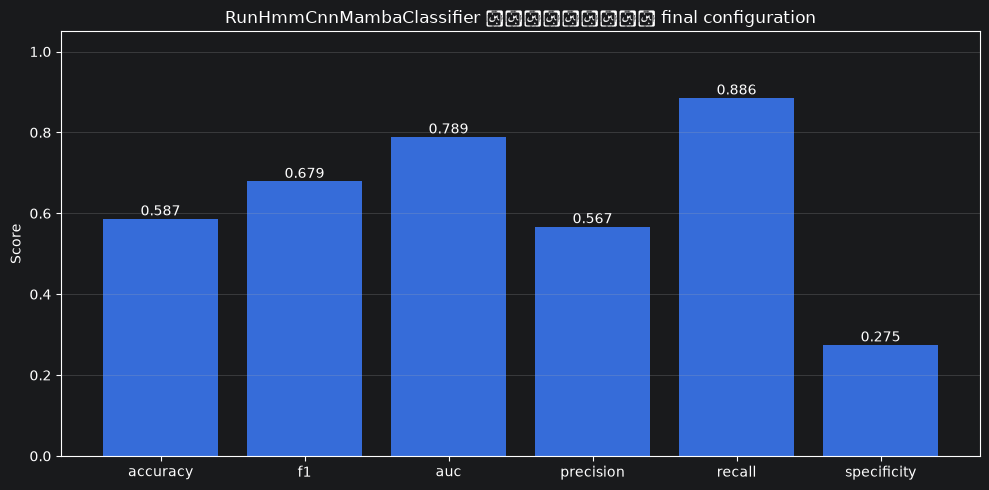


=== FINAL CONFIGURATION ===
Accuracy: 0.5867
F1: 0.6795
Auc: 0.7893
Precision: 0.5673
Recall: 0.8857
Specificity: 0.2750


In [2]:
# RUN HMM CNN MAMBA CLASSIFIER

runner = RunHmmCnnMambaClassifier(
    data_root=_project_path(
        "PaHaW/PaHaW/PaHaW_public"
    ),

    metadata_path=_project_path(
        "PaHaW/PaHaW/PaHaW_files/corpus_PaHaW.xlsx"
    ),

    # =====================================================
    # Configurazione dati
    # =====================================================

    tasks=[1, 8],

    feature_names=("x", "y"),

    engineered_features=(
        "pressure_derivative",
    ),

    # =====================================================
    # Training
    # =====================================================

    epochs=50,

    batch_size=16,

    learning_rate=1e-4,

    regularization=1e-3,

    # =====================================================
    # HMM
    # =====================================================

    n_states=2,
    covariance_type="diag",
    n_iter=50,
    tol=1e-2,
    random_state=42,
    algorithm="viterbi",
    verbose=False,

    n_splits=5,

    normalize=True,

    device=(
        "cuda"
        if torch.cuda.is_available()
        else "cpu"
    ),

    output_dir=_project_path(
        "experiments/cnn1D + mamba/"
        "hmm(train seg - val no)/task_1_8/xy_pressure_derivative"
    ),

    training_cfg={
        "metrics": [
            "accuracy",
            "f1",
            "auc",
            "precision",
            "recall",
            "specificity",
        ],

        "monitor_metric": "auc",

        "early_stopping_patience": float("inf"),

        "min_delta": 0.0,

        "normalize": True,

        "normalization_eps": 1e-6,

        "results_writer": "csv",

        "save_metrics": True,
    },
)

summary = runner.run()


# =========================================================
# RISULTATI
# =========================================================

df = pd.DataFrame([summary["averages"]])

print("\n=== Summary ===")
print(df.T)

df.to_csv(
    "hmm_cnn_mamba_final_summary.csv",
    index=False
)


# =========================================================
# PLOT
# =========================================================

metrics = [
    "val_accuracy",
    "val_f1",
    "val_auc",
    "val_precision",
    "val_recall",
    "val_specificity",
]

labels = [m.replace("val_", "") for m in metrics]
values = [summary["averages"][m] for m in metrics]

plt.figure(figsize=(10, 5))

bars = plt.bar(labels, values)

plt.bar_label(
    bars,
    fmt="%.3f"
)

plt.ylim(0, 1.05)
plt.ylabel("Score")

plt.title(
    "RunHmmCnnMambaClassifier ﷿﷿﷿﷿﷿﷿﷿﷿﷿ final configuration"
)

plt.grid(
    True,
    axis="y",
    alpha=0.3
)

plt.tight_layout()

plt.show()


# =========================================================
# FINAL METRICS
# =========================================================

print("\n=== FINAL CONFIGURATION ===")

for m, label in zip(metrics, labels):
    print(f"{label.capitalize()}: {summary['averages'][m]:.4f}")